In [ ]:

import os
import numpy as np
import math
import pymc as pm
import pymc_bart as pmb
from pymc_bart.pgbart import PGBART
from numba import njit,set_num_threads
import scipy as sp


# ==========================================
# 1. THE NUMBA ROULETTE WHEEL (SPARSITY)
# ==========================================
@njit(fastmath=True)
def sample_feature(alpha_vec):
    total_weight = np.sum(alpha_vec)
    r = np.random.uniform(0.0, total_weight)
    cumulative = 0.0
    for i in range(len(alpha_vec)):
        cumulative += alpha_vec[i]
        if r <= cumulative:
            return i
    return len(alpha_vec) - 1

@njit(fastmath=True)
def get_split_counts(F, num_features):
    counts = np.zeros(num_features, dtype=np.int32)
    m_trees = F.shape[0]
    max_nodes = F.shape[1]
    for m in range(m_trees):
        for i in range(max_nodes):
            feat = F[m, i]
            if feat != -1: counts[feat] += 1
    return counts

# ==========================================
# 2. THE MUTATIONS
# ==========================================
@njit(fastmath=True)
def get_active_leaves(F_tree, current_node_count):
    leaves = np.empty(current_node_count, dtype=np.int16)
    leaf_count = 0
    for i in range(current_node_count):
        if F_tree[i] == -1:
            leaves[leaf_count] = i
            leaf_count += 1
    return leaves[:leaf_count]

@njit(fastmath=True)
def is_split_valid(X, F_tree, T_tree, L_tree, R_tree, target_node, split_feat, split_val, min_node_size):
    n_rows = X.shape[0]
    left_count = 0
    right_count = 0
    
    for i in range(n_rows):
        node = 0
        # Drop observation down the tree until it hits a leaf OR our target node
        while F_tree[node] != -1 and node != target_node:
            if X[i, F_tree[node]] <= T_tree[node]:
                node = L_tree[node]
            else:
                node = R_tree[node]
                
        # If the observation landed in the node we are trying to split...
        if node == target_node:
            if X[i, split_feat] <= split_val:
                left_count += 1
            else:
                right_count += 1
                
    # The split is only valid if BOTH new leaves have enough data
    return (left_count >= min_node_size) and (right_count >= min_node_size)

@njit(fastmath=True)
def propose_grow(tree_idx, X, F, T, L, R, V, D, node_counts, alpha_vec, leaf_prior_std, min_node_size):
    current_count = node_counts[tree_idx]
    leaves = get_active_leaves(F[tree_idx], current_count)
    if current_count >= F.shape[1] - 1: return False, -1 
        
    random_idx = np.random.randint(0, len(leaves))
    leaf_to_split = leaves[random_idx]
    
    # NEW: Sparsity-aware feature selection
    split_feature = sample_feature(alpha_vec)
    feat_min, feat_max = np.min(X[:, split_feature]), np.max(X[:, split_feature])
    split_value = np.random.uniform(feat_min, feat_max)

    # NEW: Validate the split against the data!
    if not is_split_valid(X, F[tree_idx], T[tree_idx], L[tree_idx], R[tree_idx], 
                          leaf_to_split, split_feature, split_value, min_node_size):
        return False, -1 # Reject instantly if it isolates too few observations
    
    left_child_idx, right_child_idx = current_count, current_count + 1
    
    F[tree_idx, leaf_to_split] = split_feature
    T[tree_idx, leaf_to_split] = split_value
    L[tree_idx, leaf_to_split] = left_child_idx
    R[tree_idx, leaf_to_split] = right_child_idx
    F[tree_idx, left_child_idx] = -1
    F[tree_idx, right_child_idx] = -1
    
    # NEW: Update the Depth pointer
    parent_depth = D[tree_idx, leaf_to_split]
    D[tree_idx, left_child_idx] = parent_depth + 1
    D[tree_idx, right_child_idx] = parent_depth + 1

    # NEW: Inherit parent's value and add noise to the new leaves!
    parent_val = V[tree_idx, leaf_to_split]
    # V[tree_idx, left_child_idx] = parent_val + np.random.normal(0.0, leaf_prior_std)
    # V[tree_idx, right_child_idx] = parent_val + np.random.normal(0.0, leaf_prior_std)
    V[tree_idx, left_child_idx] = np.random.normal(0.0, leaf_prior_std)
    V[tree_idx, right_child_idx] = np.random.normal(0.0, leaf_prior_std)
    
    
    node_counts[tree_idx] += 2
    return True, leaf_to_split

@njit(fastmath=True)
def get_prunable_nodes(F_tree, L_tree, R_tree, current_node_count):
    prunable = np.empty(current_node_count, dtype=np.int16)
    count = 0
    for i in range(current_node_count):
        if F_tree[i] != -1:
            left, right = L_tree[i], R_tree[i]
            if left != -1 and right != -1:
                if F_tree[left] == -1 and F_tree[right] == -1:
                    prunable[count] = i
                    count += 1
    return prunable[:count]

@njit(fastmath=True)
def propose_prune(tree_idx, F, L, R, V, node_counts, leaf_prior_std):
    current_count = node_counts[tree_idx]
    prunable_nodes = get_prunable_nodes(F[tree_idx], L[tree_idx], R[tree_idx], current_count)
    if len(prunable_nodes) == 0: return False, -1, -1
        
    random_idx = np.random.randint(0, len(prunable_nodes))
    node_to_prune = prunable_nodes[random_idx]
    old_feature = F[tree_idx, node_to_prune]
    
    F[tree_idx, node_to_prune] = -1
    V[tree_idx, node_to_prune] = np.random.normal(0.0, leaf_prior_std)
    return True, node_to_prune, old_feature

@njit(fastmath=True)
def get_internal_nodes(F_tree, current_node_count):
    internal = np.empty(current_node_count, dtype=np.int16)
    count = 0
    for i in range(current_node_count):
        if F_tree[i] != -1:
            internal[count] = i
            count += 1
    return internal[:count]

@njit(fastmath=True)
def propose_change(tree_idx, X, F, T, L, R, node_counts, alpha_vec, min_node_size):
    current_count = node_counts[tree_idx]
    internal_nodes = get_internal_nodes(F[tree_idx], current_count)
    if len(internal_nodes) == 0: return False, -1, -1, 0.0
        
    random_idx = np.random.randint(0, len(internal_nodes))
    node_to_change = internal_nodes[random_idx]
    
    old_feature = F[tree_idx, node_to_change]
    old_threshold = T[tree_idx, node_to_change]
    
    # NEW: Sparsity-aware feature selection
    new_feature = sample_feature(alpha_vec)
    feat_min, feat_max = np.min(X[:, new_feature]), np.max(X[:, new_feature])
    new_threshold = np.random.uniform(feat_min, feat_max)
    if not is_split_valid(X, F[tree_idx], T[tree_idx], L[tree_idx], R[tree_idx], 
                          node_to_change, new_feature, new_threshold, min_node_size):
        return False, -1, -1, 0.0 # Reject the change
    
    F[tree_idx, node_to_change] = new_feature
    T[tree_idx, node_to_change] = new_threshold
    
    return True, node_to_change, old_feature, old_threshold


@njit(fastmath=True)
def propose_leaf_change(tree_idx, F, V, node_counts, leaf_prior_std, step_size):
    current_count = node_counts[tree_idx]
    leaves = get_active_leaves(F[tree_idx], current_count)
    if len(leaves) == 0: return False, -1, 0.0, 0.0
    
    random_idx = np.random.randint(0, len(leaves))
    leaf_to_change = leaves[random_idx]
    
    old_val = V[tree_idx, leaf_to_change]
    new_val = old_val + np.random.normal(0.0, step_size)
    V[tree_idx, leaf_to_change] = new_val

    var = leaf_prior_std ** 2
    penalty = (-0.5 * (new_val ** 2) / var) - (-0.5 * (old_val ** 2) / var)
    # Propose a random walk jump for the latent score
    # new_val = old_val + np.random.normal(0.0, leaf_prior_std)
    # new_val = np.random.normal(0.0, leaf_prior_std)
    # V[tree_idx, leaf_to_change] = new_val
    
    return True, leaf_to_change, old_val, penalty


@njit(fastmath=True)
def update_leaves_gibbs(X, Z, partial_pred, F_tree, T_tree, L_tree, R_tree, V_tree, leaf_prior_std):
    n_rows = X.shape[0]
    max_nodes = V_tree.shape[0]
    
    sum_res = np.zeros(max_nodes, dtype=np.float32)
    count = np.zeros(max_nodes, dtype=np.int32)
    
    # 1. Drop all observations down the tree to find their leaf node
    for i in range(n_rows):
        node = 0
        while F_tree[node] != -1:
            if X[i, F_tree[node]] <= T_tree[node]:
                node = L_tree[node]
            else:
                node = R_tree[node]
        
        # Accumulate the residual in the leaf
        res = Z[i] - partial_pred[i]
        sum_res[node] += res
        count[node] += 1
        
    tau2 = leaf_prior_std ** 2
    
    # 2. Update every active leaf directly from the exact posterior!
    for node in range(max_nodes):
        if F_tree[node] == -1 and count[node] > 0:
            n = count[node]
            
            # The Exact Gaussian Conjugate Posterior Math
            post_var = tau2 / (1.0 + n * tau2)
            post_mean = post_var * sum_res[node]
            
            # Draw the new leaf value with perfect mathematical variance
            V_tree[node] = post_mean + np.random.normal(0.0, math.sqrt(post_var))

# ==========================================
# 3. LIKELIHOOD AND PRIORS
# ==========================================
@njit(fastmath=True)
def get_tree_prediction(X, F_tree, T_tree, L_tree, R_tree, V_tree):
    n_rows = X.shape[0]
    preds = np.zeros(n_rows, dtype=np.float32)
    for i in range(n_rows):
        node = 0
        while F_tree[node] != -1:
            if X[i, F_tree[node]] <= T_tree[node]:
                node = L_tree[node]
            else:
                node = R_tree[node]
        preds[i] = V_tree[node]
    return preds

@njit(fastmath=True)
def calc_probit_loglik(Y, partial_pred, tree_pred):
    n_rows = Y.shape[0]
    log_lik = 0.0
    sqrt2 = 1.4142135623730951 
    for i in range(n_rows):
        eta = partial_pred[i] + tree_pred[i]
        p = 0.5 * (1.0 + math.erf(eta / sqrt2))
        if p < 1e-12: p = 1e-12
        elif p > 1.0 - 1e-12: p = 1.0 - 1e-12
        if Y[i] == 1: log_lik += math.log(p)
        else: log_lik += math.log(1.0 - p)
    return log_lik

@njit(fastmath=True)
def calc_gaussian_loglik(Z, partial_pred, tree_pred):
    n_rows = Z.shape[0]
    log_lik = 0.0
    for i in range(n_rows):
        eta = partial_pred[i] + tree_pred[i]
        residual = Z[i] - eta
        # Gaussian log-likelihood proportional to -0.5 * SSE
        # (Assuming variance of the latent Probit Z is fixed at 1.0)
        log_lik -= 0.5 * (residual * residual) 
    return log_lik

@njit(fastmath=True)
def calc_grow_prior_ratio(node_depth, leaf_priors):
    # SAFETY 1: If the tree tries to grow deeper than the prior allows, crush it.
    if node_depth + 1 >= len(leaf_priors):
        return -1e9  # Massive negative log-penalty (guarantees rejection)
        
    p_leaf_d = leaf_priors[node_depth]
    p_leaf_d_plus_1 = leaf_priors[node_depth + 1]
    
    p_split = 1.0 - p_leaf_d
    
    # SAFETY 2: Prevent Division by Zero or Log(0)
    if p_leaf_d <= 0.0 or p_split <= 0.0:
        return -1e9
        
    prior_ratio = (p_split * (p_leaf_d_plus_1 ** 2)) / p_leaf_d
    return math.log(prior_ratio)



def draw_latent_z(Y, current_eta):
    """
    Y: True binary array (0s and 1s)
    current_eta: The current sum of the trees (predictions)
    """
    # Initialize Z array
    Z = np.zeros_like(current_eta)
    
    # For Y == 1, draw from Normal(eta, 1) truncated to [0, infinity]
    idx1 = (Y == 1)
    if np.any(idx1):
        # stats.truncnorm uses bounds defined relative to the standard normal
        a_bounds = (0.0 - current_eta[idx1]) / 1.0
        Z[idx1] = sp.stats.truncnorm.rvs(a=a_bounds, b=np.inf, loc=current_eta[idx1], scale=1.0)
        
    # For Y == 0, draw from Normal(eta, 1) truncated to [-infinity, 0]
    idx0 = (Y == 0)
    if np.any(idx0):
        b_bounds = (0.0 - current_eta[idx0]) / 1.0
        Z[idx0] = sp.stats.truncnorm.rvs(a=-np.inf, b=b_bounds, loc=current_eta[idx0], scale=1.0)
        
    return Z

@njit(fastmath=True)
def mcmc_fractional_sweep(X, Z, F, T, L, R, V, D, node_counts, 
                          sum_trees, alpha_vec, 
                          leaf_priors, leaf_prior_std,
                          step_size,
                          accept_stats,
                          update_fraction=0.1,
                          min_node_size = 5):
    m_trees = F.shape[0]


    # 1. Determine how many trees to mutate
    n_to_update = max(1, int(m_trees * update_fraction))
    
    # 2. Creat a shuffled array of tree indices
    indices = np.arange(m_trees)
    np.random.shuffle(indices)
    trees_to_update = indices[:n_to_update]
    
    # 3. Only loop through the chosen subset
    for m in trees_to_update:
        accept_stats[0] += 1
        old_tree_pred = get_tree_prediction(X, F[m], T[m], L[m], R[m], V[m])
        partial_pred = sum_trees - old_tree_pred
        # old_ll = calc_probit_loglik(Y, partial_pred, old_tree_pred)
        old_ll = calc_gaussian_loglik(Z, partial_pred, old_tree_pred)
        
        step_type = np.random.random()
        mutation_type = -1  
        success = False
        penalty = 0.0
        
        if step_type < 0.25:
            success, mutated_node = propose_grow(m, X, F, T, L, R, V, D, node_counts, alpha_vec, leaf_prior_std, min_node_size)
            if success: penalty = calc_grow_prior_ratio(D[m, mutated_node], leaf_priors)
            mutation_type = 0
        elif step_type < 0.50:
            success, mutated_node, old_feat = propose_prune(m, F, L, R, V, node_counts, leaf_prior_std)
            if success: penalty = -calc_grow_prior_ratio(D[m, mutated_node], leaf_priors)
            mutation_type = 1
        elif step_type < 0.75:
            success, mutated_node, old_feat, old_thresh = propose_change(m, X, F, T, L, R, node_counts, alpha_vec, min_node_size)
            mutation_type = 2
        else:
            success, mutated_node, old_v, leaf_penalty = propose_leaf_change(m, F, V, node_counts, leaf_prior_std, step_size)
            if success: 
                penalty = leaf_penalty
            mutation_type = 3
            # success, mutated_node, old_v = propose_leaf_change(m, F, V, node_counts, leaf_prior_std)
            # mutation_type = 3
            
        if not success: continue
            
        new_tree_pred = get_tree_prediction(X, F[m], T[m], L[m], R[m], V[m])
        new_ll = calc_gaussian_loglik(Z, partial_pred, new_tree_pred)
        # new_ll = calc_probit_loglik(Y, partial_pred, new_tree_pred)
        
        
        log_alpha = (new_ll - old_ll) + penalty
        accept = math.log(np.random.random()) < log_alpha
        
        if accept:
            sum_trees[:] = partial_pred + new_tree_pred
            accept_stats[1] += 1                        # tracking
        else:
            if mutation_type == 0:
                F[m, mutated_node] = -1
                node_counts[m] -= 2
            elif mutation_type == 1:
                F[m, mutated_node] = old_feat
            elif mutation_type == 2:
                F[m, mutated_node] = old_feat
                T[m, mutated_node] = old_thresh
            elif mutation_type == 3:
                V[m, mutated_node] = old_v
            sum_trees[:] = partial_pred + old_tree_pred

        update_leaves_gibbs(X, Z, partial_pred, F[m], T[m], L[m], R[m], V[m], leaf_prior_std)
        
        # Update the global sum array with the fresh, perfectly variant Gibbs leaves
        final_gibbs_pred = get_tree_prediction(X, F[m], T[m], L[m], R[m], V[m])
        sum_trees[:] = partial_pred + final_gibbs_pred
        
# ==========================================
# 5. PYTHON API HANDOFF
# ==========================================
class FastTreeState:
    def __init__(self, m_trees, init_mean, max_nodes=255):
        self.m_trees = m_trees
        self.max_nodes = max_nodes
        self.F = np.full((m_trees, max_nodes), -1, dtype=np.int16)
        self.L = np.full((m_trees, max_nodes), -1, dtype=np.int16)
        self.R = np.full((m_trees, max_nodes), -1, dtype=np.int16)
        
        # THE FIX: Root node starts at Depth 1 to match PyMC's prior array
        self.D = np.ones((m_trees, max_nodes), dtype=np.int8) 
        
        self.T = np.zeros((m_trees, max_nodes), dtype=np.float32)
        self.V = np.zeros((m_trees, max_nodes), dtype=np.float32)
        self.node_counts = np.ones(m_trees, dtype=np.int16)
        self.V[:, 0] = init_mean / m_trees


class FastSurvMHBART(PGBART):
    def __init__(self, vars, target_x=None, 
                 target_y=None, use_sparsity=True, 
                 update_fraction=1.0, 
                 k=2,
                 step_size=.1,
                 min_node_size=5,
                 offset = None,
                 return_estimates=False, *args, **kwargs):
        # 1. Initialize the parent class to set up the PyMC hooks
        super().__init__(vars, *args, **kwargs)
        
        self.accept_count = 0
        self.total_count = 0
        self.use_sparsity = use_sparsity
        self.update_fraction = update_fraction
        self.min_node_size = min_node_size
        # self.return_estimates = return_estimates
        
        # 2. THE EXPLICIT OVERRIDE: 
        # Use the injected massive data, or fall back to the graph's self.X / self.Y
        # actual_X = target_x if target_x is not None else self.X
        # actual_Y = target_y if target_y is not None else self.Y
        if target_x is None or target_y is None or return_estimates == True:
            actual_X = self.X
            actual_Y = self.Y
            self.return_estimates = True
            print("returning estimates")
        else:
            self.return_estimates = False
            actual_X = target_x
            actual_Y=target_y
        
        if offset == None:
            base_prob = np.clip(actual_Y.mean(), 1e-5, 1.0 - 1e-5)
            self.offset = sp.stats.norm.ppf(base_prob)
        else:
            self.offset = offset
        
        self.c_tree_state = FastTreeState(m_trees=self.m, init_mean=0.0)
        self.flat_sum_trees = np.zeros(actual_X.shape[0], dtype=np.float32)
        # self.flat_sum_trees = np.full(actual_X.shape[0], latent_init, dtype=np.float32)

        # self.k = 1.0 # Or whatever tuning you want (lower = less shrinkage)
        # self.leaf_prior_std = np.float32(3.0 / (self.k * np.sqrt(self.m)))
        self.k = k
        self.leaf_prior_std = float(3.0 / (self.k * np.sqrt(self.m)))

        self.step_size = step_size

        self.numba_X = np.copy(np.ascontiguousarray(actual_X))
        self.numba_Y = np.copy(np.ascontiguousarray(actual_Y)).ravel()
                
        
        self.alpha_vec = np.ones(actual_X.shape[1], dtype=np.float32)
        self.numba_leaf_priors = np.array(self.prior_prob_leaf_node, dtype=np.float32)
        self.stats_dtypes = [{
            "variable_inclusion": np.ndarray,
            "tune": bool,
            "F_trees": np.ndarray,
            "T_trees": np.ndarray,
            "L_trees": np.ndarray,
            "R_trees": np.ndarray,
            "V_trees": np.ndarray,
            "node_counts": np.ndarray
        }]
        # tracking only
        self.accept_stats = np.zeros(2, dtype=np.int64)

    def astep(self, q0):
        current_eta = self.flat_sum_trees + self.offset

        # NEW: Draw the continuous latent variable Z based on current predictions
        Z = np.zeros_like(self.flat_sum_trees)
        
        # For Y == 1, draw from Normal(eta, 1) truncated to [0, infinity]
        idx1 = (self.numba_Y == 1)
        if np.any(idx1):
            a_bounds = (0.0 - current_eta[idx1]) / 1.0
            Z[idx1] = sp.stats.truncnorm.rvs(a=a_bounds, b=np.inf, loc=current_eta[idx1], scale=1.0)
            
        # For Y == 0, draw from Normal(eta, 1) truncated to [-infinity, 0]
        idx0 = (self.numba_Y == 0)
        if np.any(idx0):
            b_bounds = (0.0 - current_eta[idx0]) / 1.0
            Z[idx0] = sp.stats.truncnorm.rvs(a=-np.inf, b=b_bounds, loc=current_eta[idx0], scale=1.0)
            
        # Ensure Z is contiguous for Numba
        Z_residual = Z - self.offset
        Z_numba = np.ascontiguousarray(Z_residual, dtype=np.float32)

        # CHANGE: Pass Z_numba instead of self.numba_Y
        mcmc_fractional_sweep(
            self.numba_X, Z_numba, 
            self.c_tree_state.F, self.c_tree_state.T, 
            self.c_tree_state.L, self.c_tree_state.R, 
            self.c_tree_state.V, self.c_tree_state.D, 
            self.c_tree_state.node_counts,
            self.flat_sum_trees, 
            self.alpha_vec, 
            self.numba_leaf_priors,
            self.leaf_prior_std,
            self.step_size,
            self.accept_stats,
            self.update_fraction,
            self.min_node_size
        )
        
        var_counts = get_split_counts(self.c_tree_state.F, self.num_variates)
        
        if self.tune and self.use_sparsity:
            if self.iter > self.m:
                self.alpha_vec += var_counts.astype(np.float32)
        
        stats = {
            "variable_inclusion": var_counts, 
            "tune": self.tune,
            "F_trees": self.c_tree_state.F.copy(),
            "T_trees": self.c_tree_state.T.copy(),
            "L_trees": self.c_tree_state.L.copy(),
            "R_trees": self.c_tree_state.R.copy(),
            "V_trees": self.c_tree_state.V.copy(),
            "node_counts": self.c_tree_state.node_counts.copy()
        }

        # tracking
        # if self.accept_stats[0] > 0:
        #     rate = self.accept_stats[1] / self.accept_stats[0]
        #     if self.accept_stats[0] % 1000 == 0:
        #         print(f"Iteration {self.accept_stats[0]} | Acceptance Rate: {rate:.3f}")
        # if not self.tune:
            # print(f"Latent range: {np.min(self.flat_sum_trees):.2f} to {np.max(self.flat_sum_trees):.2f}")
        
        if self.return_estimates == True:
            self.sum_trees[0, 0, :] = self.flat_sum_trees
            return self.sum_trees, [stats]
        else:
            return np.zeros(1), [stats]
            





@njit(fastmath=True, parallel=False)
def _fast_predict_trace(X, F, T, L, R, V):
    n_samples = F.shape[0]
    m_trees = F.shape[1]
    n_obs = X.shape[0]
    
    # Pre-allocate output matrix
    preds = np.zeros((n_samples, n_obs), dtype=np.float32)
    
    # LOOP INVERSION: Put observations inside the sample/tree loops!
    for s in range(n_samples):
        for m in range(m_trees):
            # The tree structure for [s, m] is now locked into the CPU cache line!
            f_tree = F[s, m]
            t_tree = T[s, m]
            l_tree = L[s, m]
            r_tree = R[s, m]
            v_tree = V[s, m]
            
            # Vector-friendly sweep over all observations
            for i in range(n_obs):
                node = 0
                while f_tree[node] != -1:
                    feat = f_tree[node]
                    if X[i, feat] <= t_tree[node]:
                        node = l_tree[node]
                    else:
                        node = r_tree[node]
                        
                preds[s, i] += v_tree[node]
                
    return preds

def predict_out_of_sample(trace, X_new, offset, m_trees=50, max_nodes=255, thin=1):
    """
    Extracts the serialized forest topology from a PyMC trace, 
    applies an optional thinning parameter to accelerate prediction,
    and generates predictions.
    
    Parameters:
    -----------
    thin : int
        Take every `thin` sample from the posterior. 
        e.g., thin=10 reduces 4,000 samples to 400 for a 10x speedup.
    """
    print("Starting predict layout...")
    stats = trace.sample_stats
    
    # Calculate initial raw n_samples using values.size directly
    n_samples_raw = stats["F_trees"].values.size // (m_trees * max_nodes)
    
    # ZERO-ALLOCATION FIX + SLICING VIA MEMORY VIEWS
    # By using [::thin], we slice the reshaped tensor before copy=False checks types.
    # NumPy passes this sliced stride straight down to Numba as a contiguous view.
    F = np.ascontiguousarray(stats["F_trees"].values).reshape(n_samples_raw, m_trees, max_nodes)[::thin].astype(np.int16, copy=False)
    T = np.ascontiguousarray(stats["T_trees"].values).reshape(n_samples_raw, m_trees, max_nodes)[::thin].astype(np.float32, copy=False)
    L = np.ascontiguousarray(stats["L_trees"].values).reshape(n_samples_raw, m_trees, max_nodes)[::thin].astype(np.int16, copy=False)
    R = np.ascontiguousarray(stats["R_trees"].values).reshape(n_samples_raw, m_trees, max_nodes)[::thin].astype(np.int16, copy=False)
    V = np.ascontiguousarray(stats["V_trees"].values).reshape(n_samples_raw, m_trees, max_nodes)[::thin].astype(np.float32, copy=False)
    
    # Deduce the thinned sample count that Numba will actually process
    n_samples_thinned = F.shape[0]
    
    X_numba = np.ascontiguousarray(X_new, dtype=np.float64)
    n_obs = X_new.shape[0]
    
    print(f"Processing: Dropping {n_obs} rows down {n_samples_thinned} thinned historical forests (Thin factor: {thin})...")
    raw_tree_sums = _fast_predict_trace(X_numba, F, T, L, R, V)
    latent_scores = raw_tree_sums + offset
    
    # Vectorized fast probit translation
    probabilities = sp.stats.norm.cdf(latent_scores)
    
    return probabilities

In [132]:
print("Generating Probit Friedman Data...")
N = 4000
P = 50 # 5 active features, 45 pure noise features

# Friedman requires inputs strictly in the [0, 1] interval
X_dummy = np.random.uniform(0, 1, size=(N, P))

# The classic Friedman equation
latent_raw = (
    10 * np.sin(np.pi * X_dummy[:, 0] * X_dummy[:, 1]) +  # Complex interaction
    20 * (X_dummy[:, 2] - 0.5)**2 +                       # Quadratic / U-shape
    10 * X_dummy[:, 3] +                                  # Linear strong
    5 * X_dummy[:, 4]                                     # Linear weak
)

# Standardize the latent score to prevent the Probit link from flatlining
latent_scaled = (latent_raw - np.mean(latent_raw)) / np.std(latent_raw)

# Multiply by a scalar (e.g., 1.5) to stretch it nicely across the tails
p = sp.stats.norm.cdf(latent_scaled * 1.5)
Y_dummy = np.random.binomial(1, p, size=N)

Generating Probit Friedman Data...


In [124]:
print("Generating TRUE Kang-Schafer Propensity Data...")
N = 4000

# 1. Z are the TRUE unobserved standard normal covariates
Z = np.random.normal(0, 1, size=(N, 4))

# 2. X are the OBSERVED covariates (complex non-linear transformations of Z)
# This is what BART will actually train on.
X_dummy = np.zeros((N, 4))
X_dummy[:, 0] = np.exp(Z[:, 0] / 2)
X_dummy[:, 1] = Z[:, 1] / (1 + np.exp(Z[:, 0])) + 10
X_dummy[:, 2] = (Z[:, 0] * Z[:, 2] / 25 + 0.6)**3
X_dummy[:, 3] = (Z[:, 1] + Z[:, 3] + 20)**2

# 3. The true propensity score is a LINEAR combination of the hidden Z
latent_raw = -Z[:, 0] + 0.5 * Z[:, 1] - 0.25 * Z[:, 2] - 0.1 * Z[:, 3]

# 4. Scale and apply Probit
latent_scaled = (latent_raw - np.mean(latent_raw)) / np.std(latent_raw)
p = sp.stats.norm.cdf(latent_scaled * 1.5)
Y_dummy = np.random.binomial(1, p, size=N)

Generating TRUE Kang-Schafer Propensity Data...


In [166]:
import matplotlib.pyplot as plt

# ==========================================
# 4. THE TEST RUN
# ==========================================
if __name__ == "__main__":
    import pytensor.tensor as pt
    print("Building model graph...")
    with pm.Model() as test_model:
        # ENGINE_MODE = "native" 
        # ENGINE_MODE = "fast_vanilla" 
        # ENGINE_MODE = "fast_sparse" 
        ENGINE_MODE = "fast_sparse_no_save" 

        trees = pmb.BART("trees", X=np.zeros((1,X_dummy.shape[1])), Y=np.zeros(1), m=50)
        # trees = pmb.BART("trees", X=X_dummy, Y=Y_dummy, m=100)
        
        # THE FIX: Translate latent tree scores to probabilities (Probit Link)
        prob = 0.5 * (1.0 + pt.erf(trees / pt.sqrt(2.0)))
        # prob = sp.stats.norm.pdf(trees)
        
        # THE FIX: Use Bernoulli for binary classification, NOT Normal
        obs = pm.Bernoulli("obs", p=prob, observed=Y_dummy)

        if ENGINE_MODE == "native":
            print("\n[CONFIG] Using Baseline PyMC Particle Gibbs BART...")
            custom_step = None
            
        elif ENGINE_MODE == "fast_vanilla":
            print("\n[CONFIG] Using Custom C-Engine (Uniform Feature)...")
            custom_step = FastSurvMHBART(
                vars=[trees], 
                use_sparsity=False, 
                update_fraction=.05,
                k=1.5,
                step_size = .1,
                )
            
        elif ENGINE_MODE == "fast_sparse":
            print("\n[CONFIG] Using Custom C-Engine (Dirichlet Sparsity)...")
            custom_step = FastSurvMHBART(
                vars=[trees], 
                use_sparsity=True, 
                update_fraction=.05,
                k=1.5,
                step_size=.1
                )
            
        elif ENGINE_MODE == "fast_sparse_no_save":
            print("\n[CONFIG] Using Custom C-Engine (Dirichlet Sparsity)...")
            custom_step = FastSurvMHBART(
                vars=[trees], 
                use_sparsity=False, 
                target_x = X_dummy,
                target_y = Y_dummy,
                update_fraction=1,
                k=2,
                step_size = .3,
                return_estimate = False
                )

        trace = pm.sample(
                draws=2000, 
                tune=1000, 
                chains=4, 
                cores=4,
                step=custom_step,  # If None, PyMC handles it
                # mp_ctx=mp.get_context("forkserver"),
                # blas_cores=1,
                compute_convergence_checks=False,
                progressbar=True,
                discard_tuned_samples=True
            )

Building model graph...

[CONFIG] Using Custom C-Engine (Dirichlet Sparsity)...


Multiprocess sampling (4 chains in 4 jobs)
FastSurvMHBART: [trees]


Output()

Sampling 4 chains for 1_000 tune and 2_000 draw iterations (4_000 + 8_000 draws total) took 13 seconds.


In [167]:
custom_step.offset

np.float64(0.010653371679961323)

In [134]:
import arviz as az
data = trace.sample_stats["V_trees"].values 
global_mean_v = np.mean(data, axis=(2))
print(f"Shape of averaged data: {global_mean_v.shape}")
summary = az.summary(global_mean_v)
print(summary)

Shape of averaged data: (4, 100000)
       mean        sd eti89_lb eti89_ub  ess_bulk  ess_tail r_hat mcse_mean  \
x  -4.9e-05  0.003035  -0.0049   0.0047    397237    377380  1.00   4.8e-06   

   mcse_sd  
x  3.6e-06  


In [159]:
custom_step.offset

np.float64(0.010653371679961323)

In [168]:

# wicked fast
preds = predict_out_of_sample(trace, X_dummy, custom_step.offset, m_trees=50, thin=10)

Starting predict layout...
Processing: Dropping 4000 rows down 800 thinned historical forests (Thin factor: 10)...


(-0.01, 1.01)

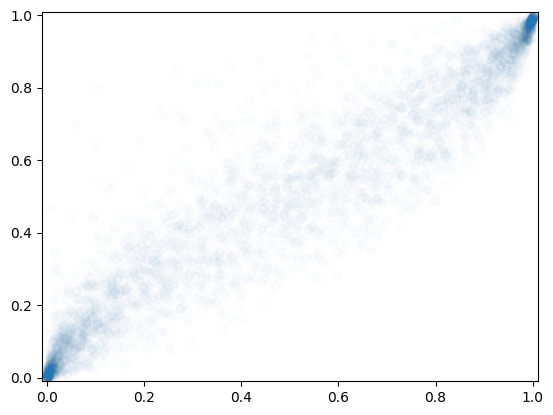

In [169]:
preds = preds.mean(0)
plt.scatter(p,preds, alpha=.01)
# # 47

plt.ylim(-.01,1.01)
plt.xlim(-0.01,1.01)

In [170]:
print(np.sqrt(((p-preds)**2).mean()))
print(np.mean(p-preds))

0.10580830523051202
-0.003733542236562125


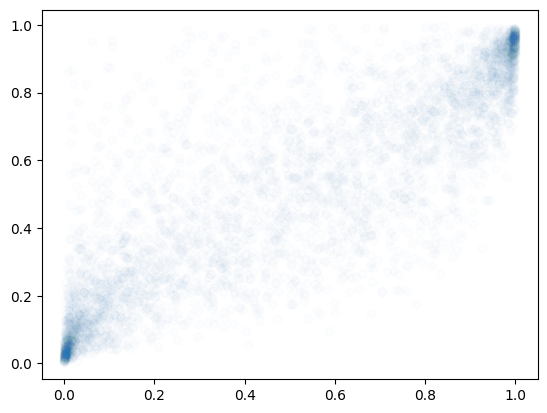

In [138]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression().fit(X_dummy, Y_dummy)
lg_pred = model.predict_proba(X_dummy)[:,1]
plt.scatter(p, lg_pred, alpha=.01)

In [139]:
print(np.sqrt(((p-lg_pred)**2).mean()))
print(np.mean(p-lg_pred))


0.18706520509573896
-0.0042650947803735
